# EDA: ERA5-Land hourly series

Loads the outputs of `pipelines/02a_eda_era5land.py` (run it, or `dvc repro`, first). ERA5-Land is reanalysis, not raw satellite imagery, and the frost label comes from the same reanalysis.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Coverage, gaps, duplicates and NaN

In [2]:
pd.read_csv(P / "eda_era5land" / "coverage.csv", index_col=0).T

point_id,el_alto,oruro,patacamaya,calamarca,caracollo,corocoro,charana,huanuni
first_utc,1985-01-01,1985-01-01,1985-01-01,1985-01-01,1985-01-01,1985-01-01,1985-01-01,1985-01-01
last_utc,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00,2026-10-26 23:00:00
hours,366576,366576,366576,366576,366576,366576,366576,366576
expected_hours,366576,366576,366576,366576,366576,366576,366576,366576
missing_hours,0,0,0,0,0,0,0,0
duplicate_timestamps,0,0,0,0,0,0,0,0
non_hourly_steps,0,0,0,0,0,0,0,0
grid_lat,-16.5,-18.0,-17.2,-17.0,-17.6,-17.2,-17.6,-18.3
grid_lon,-68.2,-67.1,-67.9,-68.1,-67.2,-69.1,-69.4,-66.8
mean_sp_hpa,638.28,647.85,627.09,629.43,641.65,630.85,622.25,616.45


## Anomaly flags by rule and field

Rules and thresholds are in `configs/frost.yaml`. Nothing is fixed or dropped.

In [3]:
pd.read_csv(P / "eda_era5land" / "anomaly_counts.csv")

,rule,field,count
0,hourly_jump,d2m_c,3818
1,hourly_jump,skt_c,1
2,hourly_jump,t2m_c,218
3,precipitation_negative,tp_mm,38321
4,ssrd_negative,ssrd_wm2,802


In [4]:
anom = pd.read_parquet(P / "anomalies.parquet")
anom.groupby(["rule", "field", "point_id"]).size().unstack(fill_value=0)

point_id                         calamarca  caracollo  charana  corocoro  el_alto  huanuni  oruro  patacamaya
rule                   field                                                                                 
hourly_jump            d2m_c           542        971      173       102       95     1696    215          24
                       skt_c             0          1        0         0        0        0      0           0
                       t2m_c             4          7       86       119        0        0      0           2
precipitation_negative tp_mm          4403       4879     5290      5112     3634     5229   5434        4340
ssrd_negative          ssrd_wm2        107        101       81        91       83      142    105          92

In [5]:
jumps = anom[(anom["rule"] == "hourly_jump") & (anom["field"] == "t2m_c")]
jumps["timestamp_utc"].dt.hour.value_counts().sort_index().rename("t2m jumps by UTC hour")

timestamp_utc
7       4
12    133
13     80
15      1
Name: t2m jumps by UTC hour, dtype: int64

## Frost frequency (nights of 1985-2025)

In [6]:
pd.read_csv(P / "eda_era5land" / "frost_by_cell.csv", index_col=0)

,nights,frost_rate,mean_tmin_c
point_id,,,
calamarca,14975,0.364274,0.892769
caracollo,14975,0.225376,2.595374
charana,14975,0.636661,-1.806402
corocoro,14975,0.505710,-0.578838
el_alto,14975,0.193189,2.337308
huanuni,14975,0.383038,0.788088
oruro,14975,0.219699,2.746821
patacamaya,14975,0.351720,1.011286


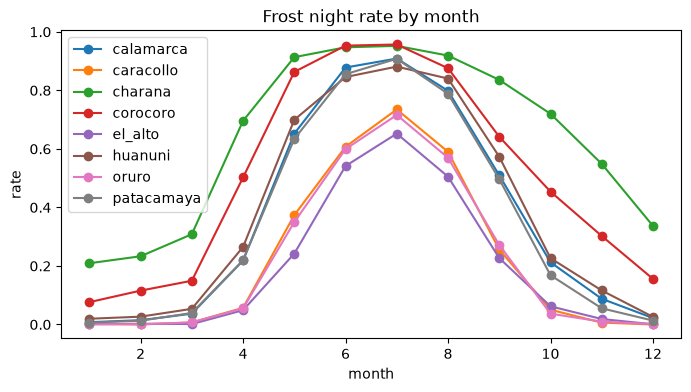

In [7]:
by_month = pd.read_csv(P / "eda_era5land" / "frost_rate_by_month.csv", index_col=0)
ax = by_month.plot(marker="o", figsize=(8, 4), title="Frost night rate by month")
ax.set_ylabel("rate"); plt.show()

## Trends 1985-2025

In [8]:
pd.read_csv(P / "eda_era5land" / "trends.csv", index_col=0).round(2)

,frost_nights_per_decade,mean_tmin_c_per_decade,frost_nights_1985_1994_mean,frost_nights_2016_2025_mean
point_id,,,,
calamarca,-6.46,0.21,139.4,117.4
caracollo,-4.32,0.14,86.6,73.5
charana,-8.34,0.35,241.9,217.3
corocoro,-8.44,0.35,196.1,167.1
el_alto,-8.05,0.20,80.7,54.4
huanuni,-8.38,0.19,151.3,124.3
oruro,-6.55,0.18,87.4,67.5
patacamaya,-8.22,0.23,137.7,110.2


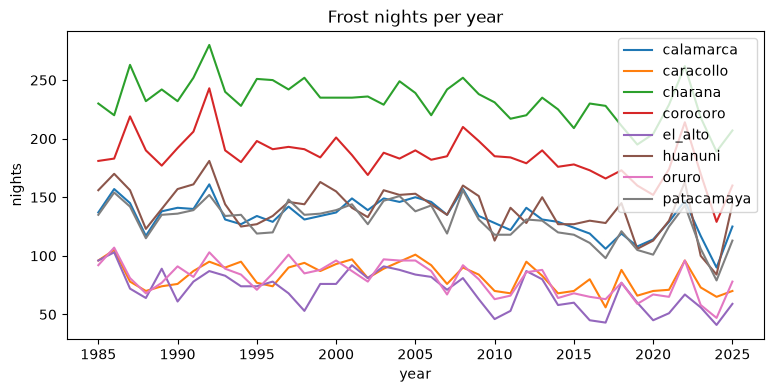

In [9]:
by_year = pd.read_csv(P / "eda_era5land" / "frost_nights_by_year.csv", index_col=0)
ax = by_year.plot(figsize=(9, 4), title="Frost nights per year")
ax.set_ylabel("nights"); plt.show()